# Module 07, Part 5: Evaluating generative models

This notebook is the runnable companion to Part 5 of the Module 07 learning content.
It checks, with code:

1. How a likelihood bound is estimated, and how the importance-weighted bound tightens as the number of samples grows.
2. How a feature-space distance (the Fréchet distance behind FID) is computed, and how it depends on the size of the sample.
3. How precision and recall separate "looks real" from "covers the data".
4. That a model that simply copies its training set can score very well on those measures, and how to catch it.
5. That reconstruction error and sample quality are different things.

There is no label to compare a generated image against, so accuracy does not apply. Everything below measures properties of a whole set of samples.

In [1]:
import math
import warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import linalg
from sklearn.datasets import load_digits
warnings.filterwarnings("ignore")
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_data(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return (torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te]))


def one_hot(y, n=10):
    return torch.nn.functional.one_hot(y, n).float()

In [3]:
class AE(nn.Module):
    """Encoder, bottleneck of size d_latent, decoder. With linear=True there are no hidden layers or activations."""

    def __init__(self, d_in=64, d_hidden=64, d_latent=2, linear=False):
        super().__init__()
        if linear:
            self.enc = nn.Linear(d_in, d_latent)
            self.dec = nn.Linear(d_latent, d_in)
        else:
            self.enc = nn.Sequential(nn.Linear(d_in, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_latent))
            self.dec = nn.Sequential(nn.Linear(d_latent, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_in))

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z)

    def forward(self, x):
        return self.decode(self.encode(x))


def train_ae(model, X, epochs=300, lr=2e-3, batch_size=64, noise=0.0, seed=0):
    """Train with mean squared error. noise > 0 corrupts the input but still rebuilds the clean image (a denoising autoencoder).
    Returns the mean loss of each epoch."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for _ in range(epochs):
        perm = torch.randperm(len(X), generator=g)
        total = 0.0
        for i in range(0, len(X), batch_size):
            xb = X[perm[i:i + batch_size]]
            xin = xb + noise * torch.randn(xb.shape, generator=g) if noise > 0 else xb
            loss = ((model(xin) - xb) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
        hist.append(total / len(X))
    return hist


@torch.no_grad()
def reconstruction_mse(model, X):
    return ((model(X) - X) ** 2).mean().item()


def pca_mse(X_train, X_eval, k):
    """Mean squared error of rebuilding X_eval from the top k principal components of X_train."""
    X_train = X_train.numpy().astype(np.float64)
    X_eval = X_eval.numpy().astype(np.float64)
    mu = X_train.mean(0)
    _, _, Vt = np.linalg.svd(X_train - mu, full_matrices=False)
    P = Vt[:k]
    rec = (X_eval - mu) @ P.T @ P + mu
    return float(((rec - X_eval) ** 2).mean())

In [4]:
class VAE(nn.Module):
    """Gaussian encoder q(z|x), Bernoulli-on-intensity decoder p(x|z). With n_classes > 0 both networks also see a one-hot label."""

    def __init__(self, d_in=64, d_hidden=64, d_latent=2, n_classes=0):
        super().__init__()
        self.d_latent, self.n_classes = d_latent, n_classes
        self.enc = nn.Sequential(nn.Linear(d_in + n_classes, d_hidden), nn.ReLU())
        self.mu = nn.Linear(d_hidden, d_latent)
        self.logvar = nn.Linear(d_hidden, d_latent)
        self.dec = nn.Sequential(nn.Linear(d_latent + n_classes, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_in))

    def encode(self, x, c=None):
        h = self.enc(x if c is None else torch.cat([x, c], 1))
        return self.mu(h), self.logvar(h)

    def decode(self, z, c=None):
        """Returns logits; apply a sigmoid to get pixel intensities."""
        return self.dec(z if c is None else torch.cat([z, c], 1))

    @staticmethod
    def reparameterize(mu, logvar, generator=None):
        eps = torch.randn(mu.shape, generator=generator)
        return mu + torch.exp(0.5 * logvar) * eps

    def forward(self, x, c=None):
        mu, logvar = self.encode(x, c)
        z = self.reparameterize(mu, logvar)
        return self.decode(z, c), mu, logvar


def kl_to_standard_normal(mu, logvar):
    """KL( N(mu, sigma^2) || N(0, 1) ) summed over latent dimensions, one value per example."""
    return 0.5 * (mu ** 2 + torch.exp(logvar) - 1.0 - logvar).sum(1)


def reconstruction_nll(logits, x):
    """Bernoulli negative log-likelihood of the pixel intensities, summed over pixels, one value per example."""
    return F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(1)


def elbo_terms(model, x, c=None):
    """One-sample estimate of the two terms of the negative ELBO, each averaged over the batch."""
    logits, mu, logvar = model(x, c)
    return reconstruction_nll(logits, x).mean(), kl_to_standard_normal(mu, logvar).mean()


def train_vae(model, X, y_onehot=None, epochs=200, lr=2e-3, batch_size=64, beta=1.0, anneal_epochs=0, seed=0):
    """Minimize recon + beta * KL. With anneal_epochs > 0, beta rises linearly from 0 to its final value over that many epochs.
    Returns a list of (reconstruction, KL) epoch averages."""
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        b = beta * min(1.0, ep / anneal_epochs) if anneal_epochs > 0 else beta
        perm = torch.randperm(len(X), generator=g)
        sr = sk = 0.0
        for i in range(0, len(X), batch_size):
            idx = perm[i:i + batch_size]
            xb = X[idx]
            cb = y_onehot[idx] if y_onehot is not None else None
            rec, kl = elbo_terms(model, xb, cb)
            loss = rec + b * kl
            opt.zero_grad()
            loss.backward()
            opt.step()
            sr += rec.item() * len(xb)
            sk += kl.item() * len(xb)
        hist.append((sr / len(X), sk / len(X)))
    return hist


@torch.no_grad()
def evaluate_terms(model, X, c=None, repeats=10, seed=0):
    """Average (reconstruction, KL) over the set, using several draws of z per example."""
    torch.manual_seed(seed)
    r = k = 0.0
    for _ in range(repeats):
        rec, kl = elbo_terms(model, X, c)
        r += rec.item() / repeats
        k += kl.item() / repeats
    return r, k


@torch.no_grad()
def iwae_bound(model, x, K=1, seed=0):
    """Importance-weighted estimate of log p(x) per example, using q(z|x) as the proposal and K samples.
    K = 1 is the ELBO. As K grows the bound tightens toward log p(x)."""
    torch.manual_seed(seed)
    mu, logvar = model.encode(x)
    std = torch.exp(0.5 * logvar)
    logw = []
    for _ in range(K):
        z = mu + std * torch.randn_like(std)
        logits = model.decode(z)
        log_px_z = -reconstruction_nll(logits, x)
        log_pz = -0.5 * (z ** 2 + math.log(2 * math.pi)).sum(1)
        log_qz = -0.5 * (((z - mu) / std) ** 2 + math.log(2 * math.pi) + logvar).sum(1)
        logw.append(log_px_z + log_pz - log_qz)
    logw = torch.stack(logw, 0)
    return torch.logsumexp(logw, 0) - math.log(K)


@torch.no_grad()
def active_units(model, X, threshold=0.01):
    """Number of latent dimensions whose posterior mean varies across the data by more than the threshold (variance)."""
    mu, _ = model.encode(X)
    return int((mu.var(0) > threshold).sum().item())

In [5]:
@torch.no_grad()
def interpolate_latent(model, x1, x2, steps=8):
    """Decode points on the straight line between the latent means of two images (autoencoder or VAE)."""
    if hasattr(model, "mu"):
        z1, z2 = model.encode(x1[None])[0], model.encode(x2[None])[0]
        dec = lambda z: torch.sigmoid(model.decode(z))
    else:
        z1, z2 = model.encode(x1[None]), model.encode(x2[None])
        dec = lambda z: model.decode(z)
    ts = torch.linspace(0, 1, steps)[:, None]
    z = (1 - ts) * z1 + ts * z2
    return dec(z)


def interpolate_pixels(x1, x2, steps=8):
    """The baseline: a straight line between the two images in pixel space."""
    ts = torch.linspace(0, 1, steps)[:, None]
    return (1 - ts) * x1[None] + ts * x2[None]


@torch.no_grad()
def decode_grid(model, lim=2.5, n=12, vae=True):
    """Decode an n by n grid of a two-dimensional latent space. Returns an array of shape (n, n, 8, 8), top row = largest z2."""
    zs = torch.linspace(-lim, lim, n)
    zz = torch.stack(torch.meshgrid(zs, zs.flip(0), indexing="xy"), -1).reshape(-1, 2)
    out = model.decode(zz)
    out = torch.sigmoid(out) if vae else out
    return out.reshape(n, n, 8, 8)


@torch.no_grad()
def sample_prior(model, n, seed=0):
    """Draw z from the standard normal prior and decode. Intensities in [0, 1]."""
    g = torch.Generator().manual_seed(seed)
    z = torch.randn(n, model.d_latent if hasattr(model, "d_latent") else model.dec[0].in_features, generator=g)
    out = model.decode(z)
    return torch.sigmoid(out) if hasattr(model, "mu") else out


@torch.no_grad()
def sample_conditional(model, digit, n, seed=0):
    """Conditional VAE: draw z from the prior and decode with the one-hot label of the requested digit."""
    g = torch.Generator().manual_seed(seed)
    z = torch.randn(n, model.d_latent, generator=g)
    c = torch.nn.functional.one_hot(torch.full((n,), digit), model.n_classes).float()
    return torch.sigmoid(model.decode(z, c))

In [6]:
class FeatureNet(nn.Module):
    """A small classifier trained on real digits. Its hidden layer plays the role Inception plays in FID."""

    def __init__(self, d_in=64, d_feat=32):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Linear(64, d_feat), nn.ReLU())
        self.head = nn.Linear(d_feat, 10)

    def features(self, x):
        return self.body(x)

    def forward(self, x):
        return self.head(self.body(x))


def train_feature_net(X, y, epochs=60, seed=0):
    torch.manual_seed(seed)
    net = FeatureNet()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            idx = perm[i:i + 64]
            loss = nn.functional.cross_entropy(net(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
    return net


@torch.no_grad()
def get_features(net, X):
    return net.features(X).numpy().astype(np.float64)


def frechet_distance(fa, fb):
    """Frechet distance between Gaussians fitted to two sets of features (the quantity behind FID)."""
    mu_a, mu_b = fa.mean(0), fb.mean(0)
    eps = 1e-6 * np.eye(fa.shape[1])
    ca, cb = np.cov(fa, rowvar=False) + eps, np.cov(fb, rowvar=False) + eps
    covmean = linalg.sqrtm(ca @ cb)
    covmean = covmean.real
    return float(((mu_a - mu_b) ** 2).sum() + np.trace(ca) + np.trace(cb) - 2 * np.trace(covmean))


def _knn_radius(F, k):
    d = np.linalg.norm(F[:, None] - F[None], axis=-1)
    return np.sort(d, axis=1)[:, k]


def precision_recall(real, fake, k=3):
    """Precision: share of generated points that land inside the real data's neighbourhood.
    Recall: share of real points that land inside the generated data's neighbourhood. (k-nearest-neighbour balls.)"""
    r_real, r_fake = _knn_radius(real, k), _knn_radius(fake, k)
    d = np.linalg.norm(fake[:, None] - real[None], axis=-1)
    precision = float((d <= r_real[None]).any(1).mean())
    recall = float((d.T <= r_fake[None]).any(1).mean())
    return precision, recall


def nearest_train_distance(samples, train):
    """Pixel-space distance from each generated image to its nearest training image. Near zero means copying."""
    d = torch.cdist(samples, train)
    return d.min(1).values

In [7]:
Xtr, ytr, Xte, yte = load_data()
net = train_feature_net(Xtr, ytr)
f_train, f_test = get_features(net, Xtr), get_features(net, Xte)
with torch.no_grad():
    print("feature network accuracy on real test images:", round((net(Xte).argmax(1) == yte).float().mean().item(), 3))

feature network accuracy on real test images: 0.972


## 1. The likelihood bound, and how to tighten it

The ELBO is a lower bound on $\log p(x)$. A tighter bound uses importance sampling: draw $K$ codes from the encoder, weight each by
$p(x, z)/q(z|x)$, and average the weights before taking the logarithm. With $K = 1$ it is the ELBO. As $K$ grows the bound rises towards $\log p(x)$ and never exceeds it.
The numbers are in nats per image under this model's pixel likelihood (a Bernoulli on pixel intensities), so they are only comparable between models that use the same likelihood.

In [8]:
torch.manual_seed(0)
vae = VAE(d_latent=8); train_vae(vae, Xtr, epochs=200, beta=1.0)
print("K        bound (nats per image, test set average)")
prev = None
for K in (1, 10, 100, 1000):
    b = iwae_bound(vae, Xte, K=K, seed=1).mean().item()
    print(f"{K:4d}     {b:9.3f}")

K        bound (nats per image, test set average)
   1       -24.477
  10       -24.220
 100       -24.183
1000       -24.180


The bound improves as $K$ grows, with diminishing returns. The gap between $K = 1$ and $K = 1000$ is an estimate of how loose the ELBO was for this model: it measures the gap in
the identity from Part 2 between the encoder's distribution and the true posterior. A likelihood number is useful for comparing two VAEs of the same family. It cannot rank a VAE against a GAN,
which has no likelihood, so the field also uses measures based on samples.

## 2. A distance between sets of images

The Fréchet distance compares the real and generated images after passing both through a fixed feature network. It fits a Gaussian to each set of features and measures how far apart the two Gaussians
are. In the standard version the network is Inception and the number is FID. Here the feature network is the small classifier trained on real digits above. A smaller distance means the two sets look
alike in the features that network cares about.

Before using it, we check how it behaves on sets we know are identical in distribution: random subsets of the real training images against the real test images.

In [9]:
rng = np.random.RandomState(0)
print("size of the real subset   Frechet distance to the real test set (mean of 10 random subsets)")
for n in (30, 60, 120, 359, 1000):
    vals = []
    for _ in range(10):
        idx = rng.choice(len(f_train), n, replace=False)
        vals.append(frechet_distance(f_train[idx], f_test))
    print(f"{n:24d}   {np.mean(vals):8.3f}")

size of the real subset   Frechet distance to the real test set (mean of 10 random subsets)


                      30     22.916
                      60     10.487
                     120      4.523
                     359      2.968
                    1000      1.671


Two sets of real digits are not at distance zero, and the distance depends on how many images you use: it is larger for small sets because the Gaussian fit is noisier. The consequence is
that a Fréchet distance is only meaningful next to another one computed with the same number of samples, and that tiny differences between models are noise. In the comparisons below, every set has 359 images, the size of the test set.

## 3. Separating quality from coverage

One number cannot say whether generated images are bad because they look wrong or because they all look alike. Precision and recall in feature space separate the two. Precision is the share of generated images that fall in the neighbourhood
of real ones (do they look real?). Recall is the share of real images that fall in the neighbourhood of generated ones (is the real variety covered?). We build seven sets of 359 images and score each one.

- real digits (a random 359 of the training set): the ceiling
- VAE with $\beta = 0.1$, $\beta = 1$ and $\beta = 4$ (the last one collapsed, as in Part 3), samples drawn from the prior
- an autoencoder with an 8-dimensional code, decoded from prior draws
- a "copier": the training images with a little noise added
- the average training image with noise added

In [10]:
def feats(s): return get_features(net, s.clamp(0, 1))
rng = np.random.RandomState(0)
sets = {}
sets["real digits"] = Xtr[torch.tensor(rng.choice(len(Xtr), 359, replace=False))]
vaes = {}
for name, beta in (("VAE beta 0.1", 0.1), ("VAE beta 1", 1.0), ("VAE beta 4 (collapsed)", 4.0)):
    v = VAE(d_latent=8); train_vae(v, Xtr, epochs=200, beta=beta, seed=0); vaes[name] = v
    sets[name] = sample_prior(v, 359, seed=1)
ae = AE(d_latent=8); train_ae(ae, Xtr, epochs=300)
sets["autoencoder, prior draws"] = ae.decode(torch.randn(359, 8, generator=torch.Generator().manual_seed(1))).detach()
g = torch.Generator().manual_seed(2)
pick = torch.tensor(rng.choice(len(Xtr), 359, replace=False))
sets["copier (train + noise)"] = Xtr[pick] + 0.02 * torch.randn(359, 64, generator=g)
sets["mean image + noise"] = Xtr.mean(0)[None] + 0.1 * torch.randn(359, 64, generator=g)

print(f"{'set':28s} Frechet  precision  recall   mean distance to nearest training image")
table = {}
for name, s in sets.items():
    fs = feats(s)
    fd = frechet_distance(f_test, fs)
    p, r = precision_recall(f_test, fs, k=3)
    nn_d = nearest_train_distance(s.clamp(0, 1), Xtr).mean().item()
    table[name] = (fd, p, r, nn_d)
    print(f"{name:28s} {fd:7.2f}  {p:9.2f}  {r:6.2f}   {nn_d:8.3f}")

set                          Frechet  precision  recall   mean distance to nearest training image
real digits                     2.54       0.94    0.91      0.000
VAE beta 0.1                   10.02       0.67    0.85      1.353
VAE beta 1                     14.48       0.88    0.48      1.156
VAE beta 4 (collapsed)        220.53       1.00    0.00      1.511


autoencoder, prior draws       98.23       0.45    0.81      2.286
copier (train + noise)          2.33       0.92    0.92      0.134
mean image + noise            138.62       0.93    0.00      1.615


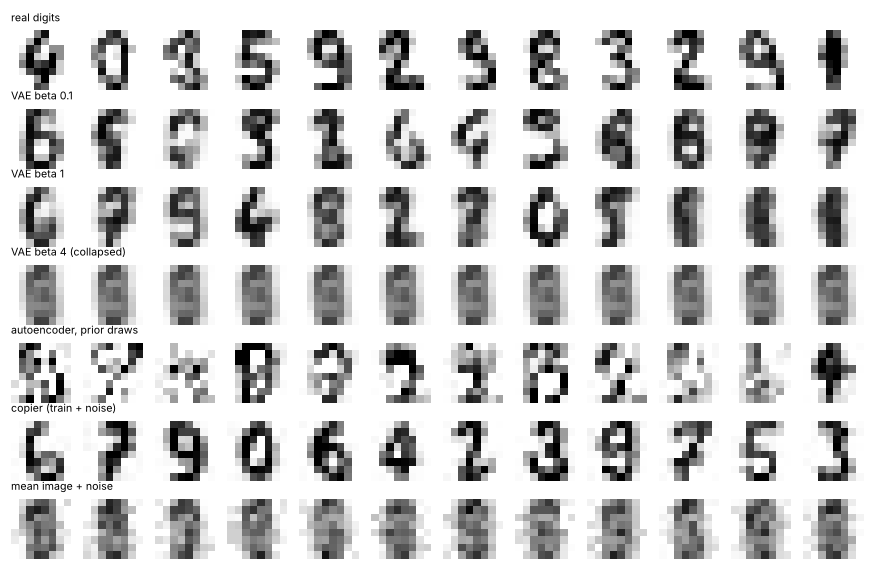

In [11]:
fig, axes = plt.subplots(len(sets), 12, figsize=(10, len(sets) * 0.9))
for i, (name, s) in enumerate(sets.items()):
    for j in range(12):
        axes[i, j].imshow(s[j].clamp(0, 1).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); axes[i, j].axis("off")
    axes[i, 0].set_title(name, fontsize=7, loc="left")
plt.show()

Reading the table with the pictures beside it:

- Real digits set the reference level for each column.
- The collapsed VAE has precision near 1 and recall near 0. Every image it makes is a convincing picture of the one thing it has learned, so none of them look wrong, and it covers almost none of the real variety. A precision score alone would have called it excellent.
- The VAE at $\beta = 0.1$ has the best recall of the VAEs and a lower precision: it covers more, and some of what it makes does not look real. That is the same trade-off as in Part 3.
- The autoencoder decoded from prior draws is far from the real data by the Fréchet distance, as Part 2 predicted.
- The copier looks as good as the real data by the Fréchet distance, precision and recall, because its images are the real data. Only the last column gives it away: its images sit a tiny distance from images the model was trained on.

## 4. Reconstruction error is not generation quality

It is easy to confuse the two, because both are called "error". They measure different things. Reconstruction error asks how well the model rebuilds an image it was given. Generation quality asks whether images
from the prior look like the data.

In [12]:
rows = []
for name in ("VAE beta 0.1", "VAE beta 1", "VAE beta 4 (collapsed)"):
    v = vaes[name]
    r, k = evaluate_terms(v, Xte)
    with torch.no_grad():
        rec_mse = ((torch.sigmoid(v.decode(v.encode(Xte)[0])) - Xte) ** 2).mean().item()
    rows.append((name, rec_mse, table[name][0]))
with torch.no_grad():
    rec_mse = ((ae(Xte) - Xte) ** 2).mean().item()
rows.append(("autoencoder", rec_mse, table["autoencoder, prior draws"][0]))
print(f"{'model':26s} reconstruction MSE (test)   Frechet distance of prior samples")
for name, r, f in rows:
    print(f"{name:26s} {r:22.4f}   {f:22.2f}")

model                      reconstruction MSE (test)   Frechet distance of prior samples
VAE beta 0.1                               0.0129                    10.02
VAE beta 1                                 0.0263                    14.48
VAE beta 4 (collapsed)                     0.0738                   220.53
autoencoder                                0.0144                    98.23


The autoencoder rebuilds images almost as well as the VAE with $\beta = 0.1$ and better than the VAEs with larger $\beta$, yet the Fréchet distance of its prior samples is several times worse than the $\beta = 1$ VAE's (and the collapsed VAE, which reconstructs worst, is worse still on samples only because it has learned nothing). A model can be an excellent compressor and a poor generator. The reconstruction error says how well the code
describes the images you have, and the quality of samples depends on whether the code space has been organized so that a draw from the prior lands somewhere meaningful.

## What to take away

- There is no right answer to compare a generated image with, so accuracy does not apply. We measure sets of images.
- A likelihood bound compares models of the same family. The importance-weighted bound tightens it, and the gap to the ELBO is a measure of how loose the ELBO was.
- A Fréchet distance depends on a feature network and on the number of samples. Compare it only to values computed the same way.
- Precision and recall separate "looks real" from "covers the data", and a single score can hide a model that is perfect at one and absent at the other.
- A model that copies its training data can score well. Check the distance to the nearest training example.
- Reconstruction error and sample quality are different questions.